# Importing libraries and set style

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

import pickle

Style setting

In [2]:
plt.style.use('seaborn-v0_8')
# plt.style.use('seaborn-v0_8-colorblind')
# sns.set_theme(style="whitegrid")

Font setting

In [3]:
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Nimbus Sans"]

In [ ]:
# Figure
plt.rcParams['figure.figsize'] = (8, 6)
# plt.rcParams['figure.dpi'] = 300

# Title
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Axes
plt.rcParams['axes.labelsize'] = 12

# Import data

In [5]:
df = pd.read_parquet("../raw_data/parquets/1-escribe.parquet")

# with open('../raw_data/pickles/.pickle', 'rb') as file:
# 	df = pickle.load(file)

# Overview on all the data

In [6]:
# df

In [7]:
df.info()

<class 'pandas.DataFrame'>
Index: 1787 entries, 212 to 1788
Data columns (total 37 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   pseudopaz               1787 non-null   string        
 1   patient_date_of_birth   1787 non-null   datetime64[ns]
 2   patient_age             1787 non-null   Int64         
 3   patient_sex             1787 non-null   string        
 4   patient_race            1787 non-null   string        
 5   acq_time                1787 non-null   datetime64[us]
 6   transmission_time       1787 non-null   datetime64[us]
 7   confirm_time            886 non-null    datetime64[us]
 8   phy_date                886 non-null    datetime64[us]
 9   site_number             1787 non-null   string        
 10  patient_location        143 non-null    string        
 11  patient_room            180 non-null    string        
 12  medications             1787 non-null   string        
 13  co

# Plots

## Functions

In [8]:
def line_plot(df, colname,
    title, x_label, y_label,
    output_dir, progr, output_name, output_format):

    births_per_year = df[colname].dt.year.value_counts().sort_index()

    births_per_year.plot()
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)

    plt.tight_layout()
    plt.savefig(f"{output_dir}/{progr}-{output_name}.{output_format}", dpi=300, bbox_inches='tight')
    plt.show()

In [9]:
def histbox_plot(df, colname,
    title, x_label, y_label,
    output_dir, progr, output_name, output_format,
    figsize, bins='auto'):

    # Create figure with 2 rows (hist + boxplot)
    fig, (ax1, ax2) = plt.subplots(
        2, 1, 
        figsize=figsize,
        sharex=True, 
        gridspec_kw={'height_ratios': [4, 1]}
    )

    # Histogram
    ax1.hist(df[colname], bins=bins)
    ax1.set_title(title)
    ax1.set_ylabel(y_label)

    # Boxplot
    ax2.boxplot(df[colname], vert=False, widths=0.6)
    ax2.set_xlabel(x_label)
    ax2.set_yticks([])  # optional: hide y-axis ticks

    plt.tight_layout()
    plt.savefig(f"{output_dir}/{progr}-{output_name}.{output_format}", dpi=300, bbox_inches='tight')
    plt.show()

### Common values

In [18]:
output_dir = '../plots/1-escribe'
# figsize = (8, 6)
progr = 0
output_format = 'pdf'

## Plot for every column

#### `patient_date_of_birth`

In [ ]:
colname = 'patient_date_of_birth'

In [ ]:
title = 'Births per year'
x_label = 'Year'
y_label = 'Number of patients'
output_name = 'birth_years'
progr += 1

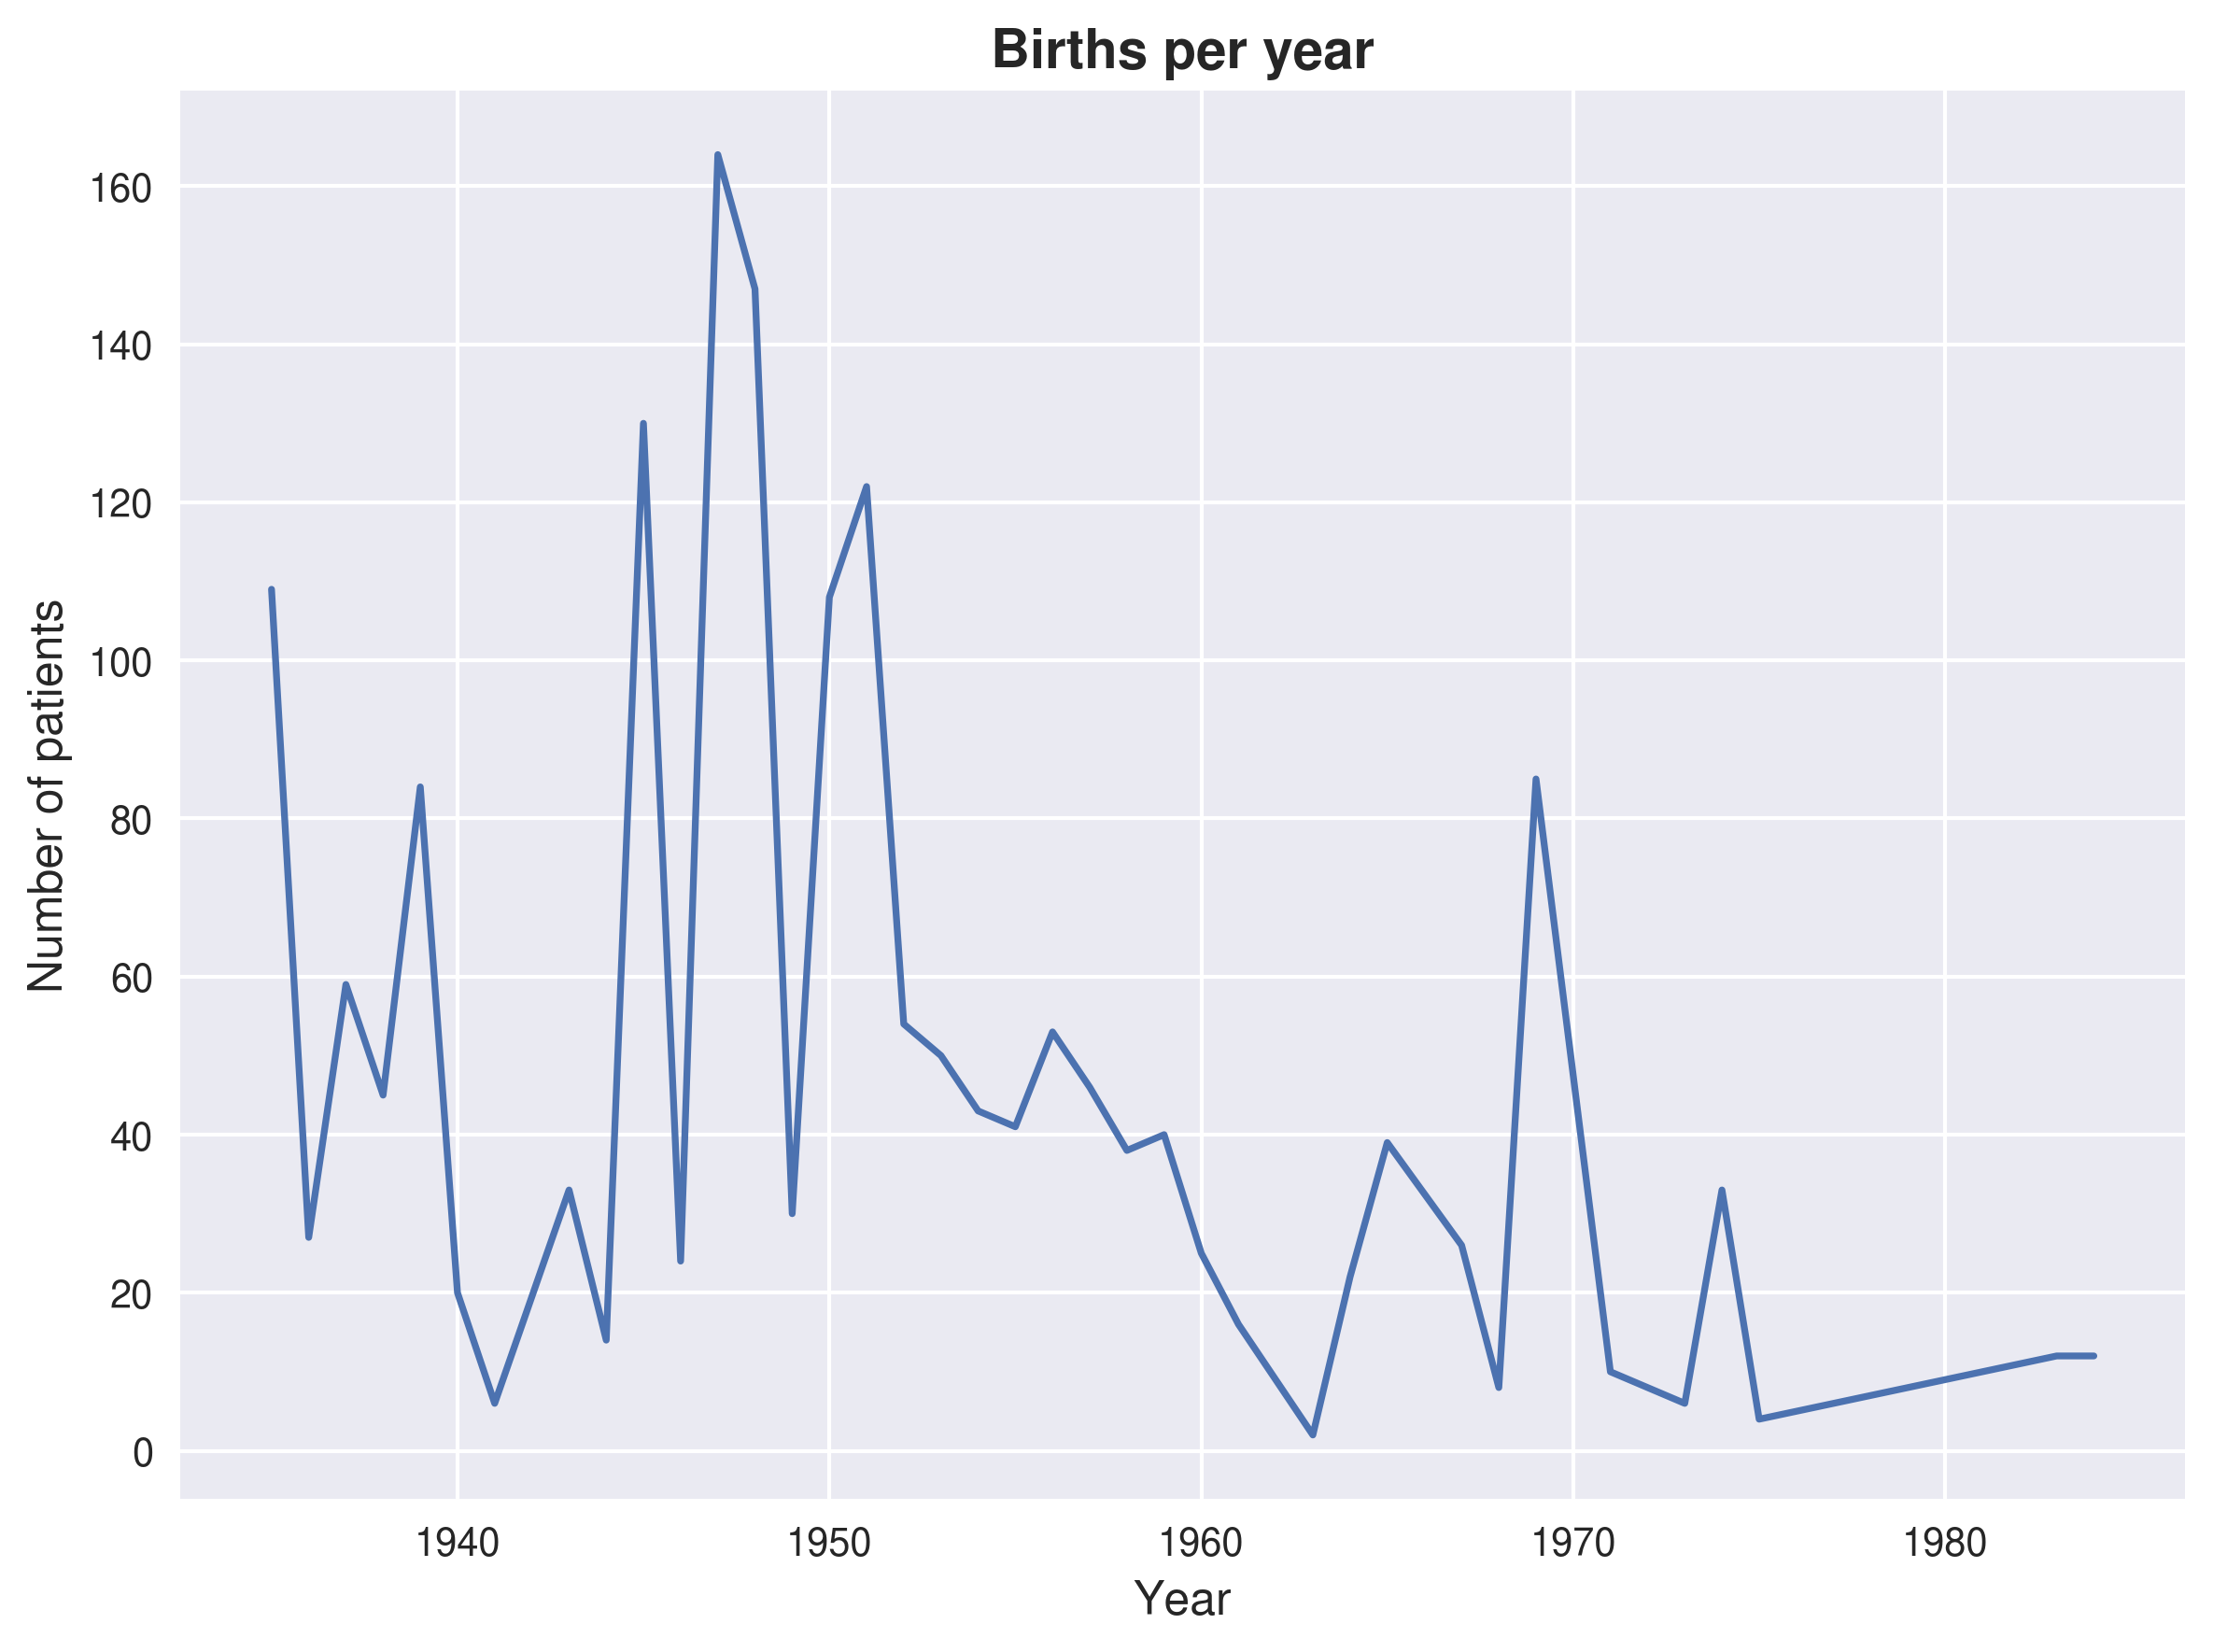

In [13]:
line_plot(df, colname,
    title, x_label, y_label,
    output_dir, progr, output_name, output_format)

#### `patient_age`

In [14]:
colname = 'patient_age'

In [ ]:
title = 'Age Distribution'
x_label = 'Age'
y_label = 'Count'
output_name = 'age_distribution'
progr += 1

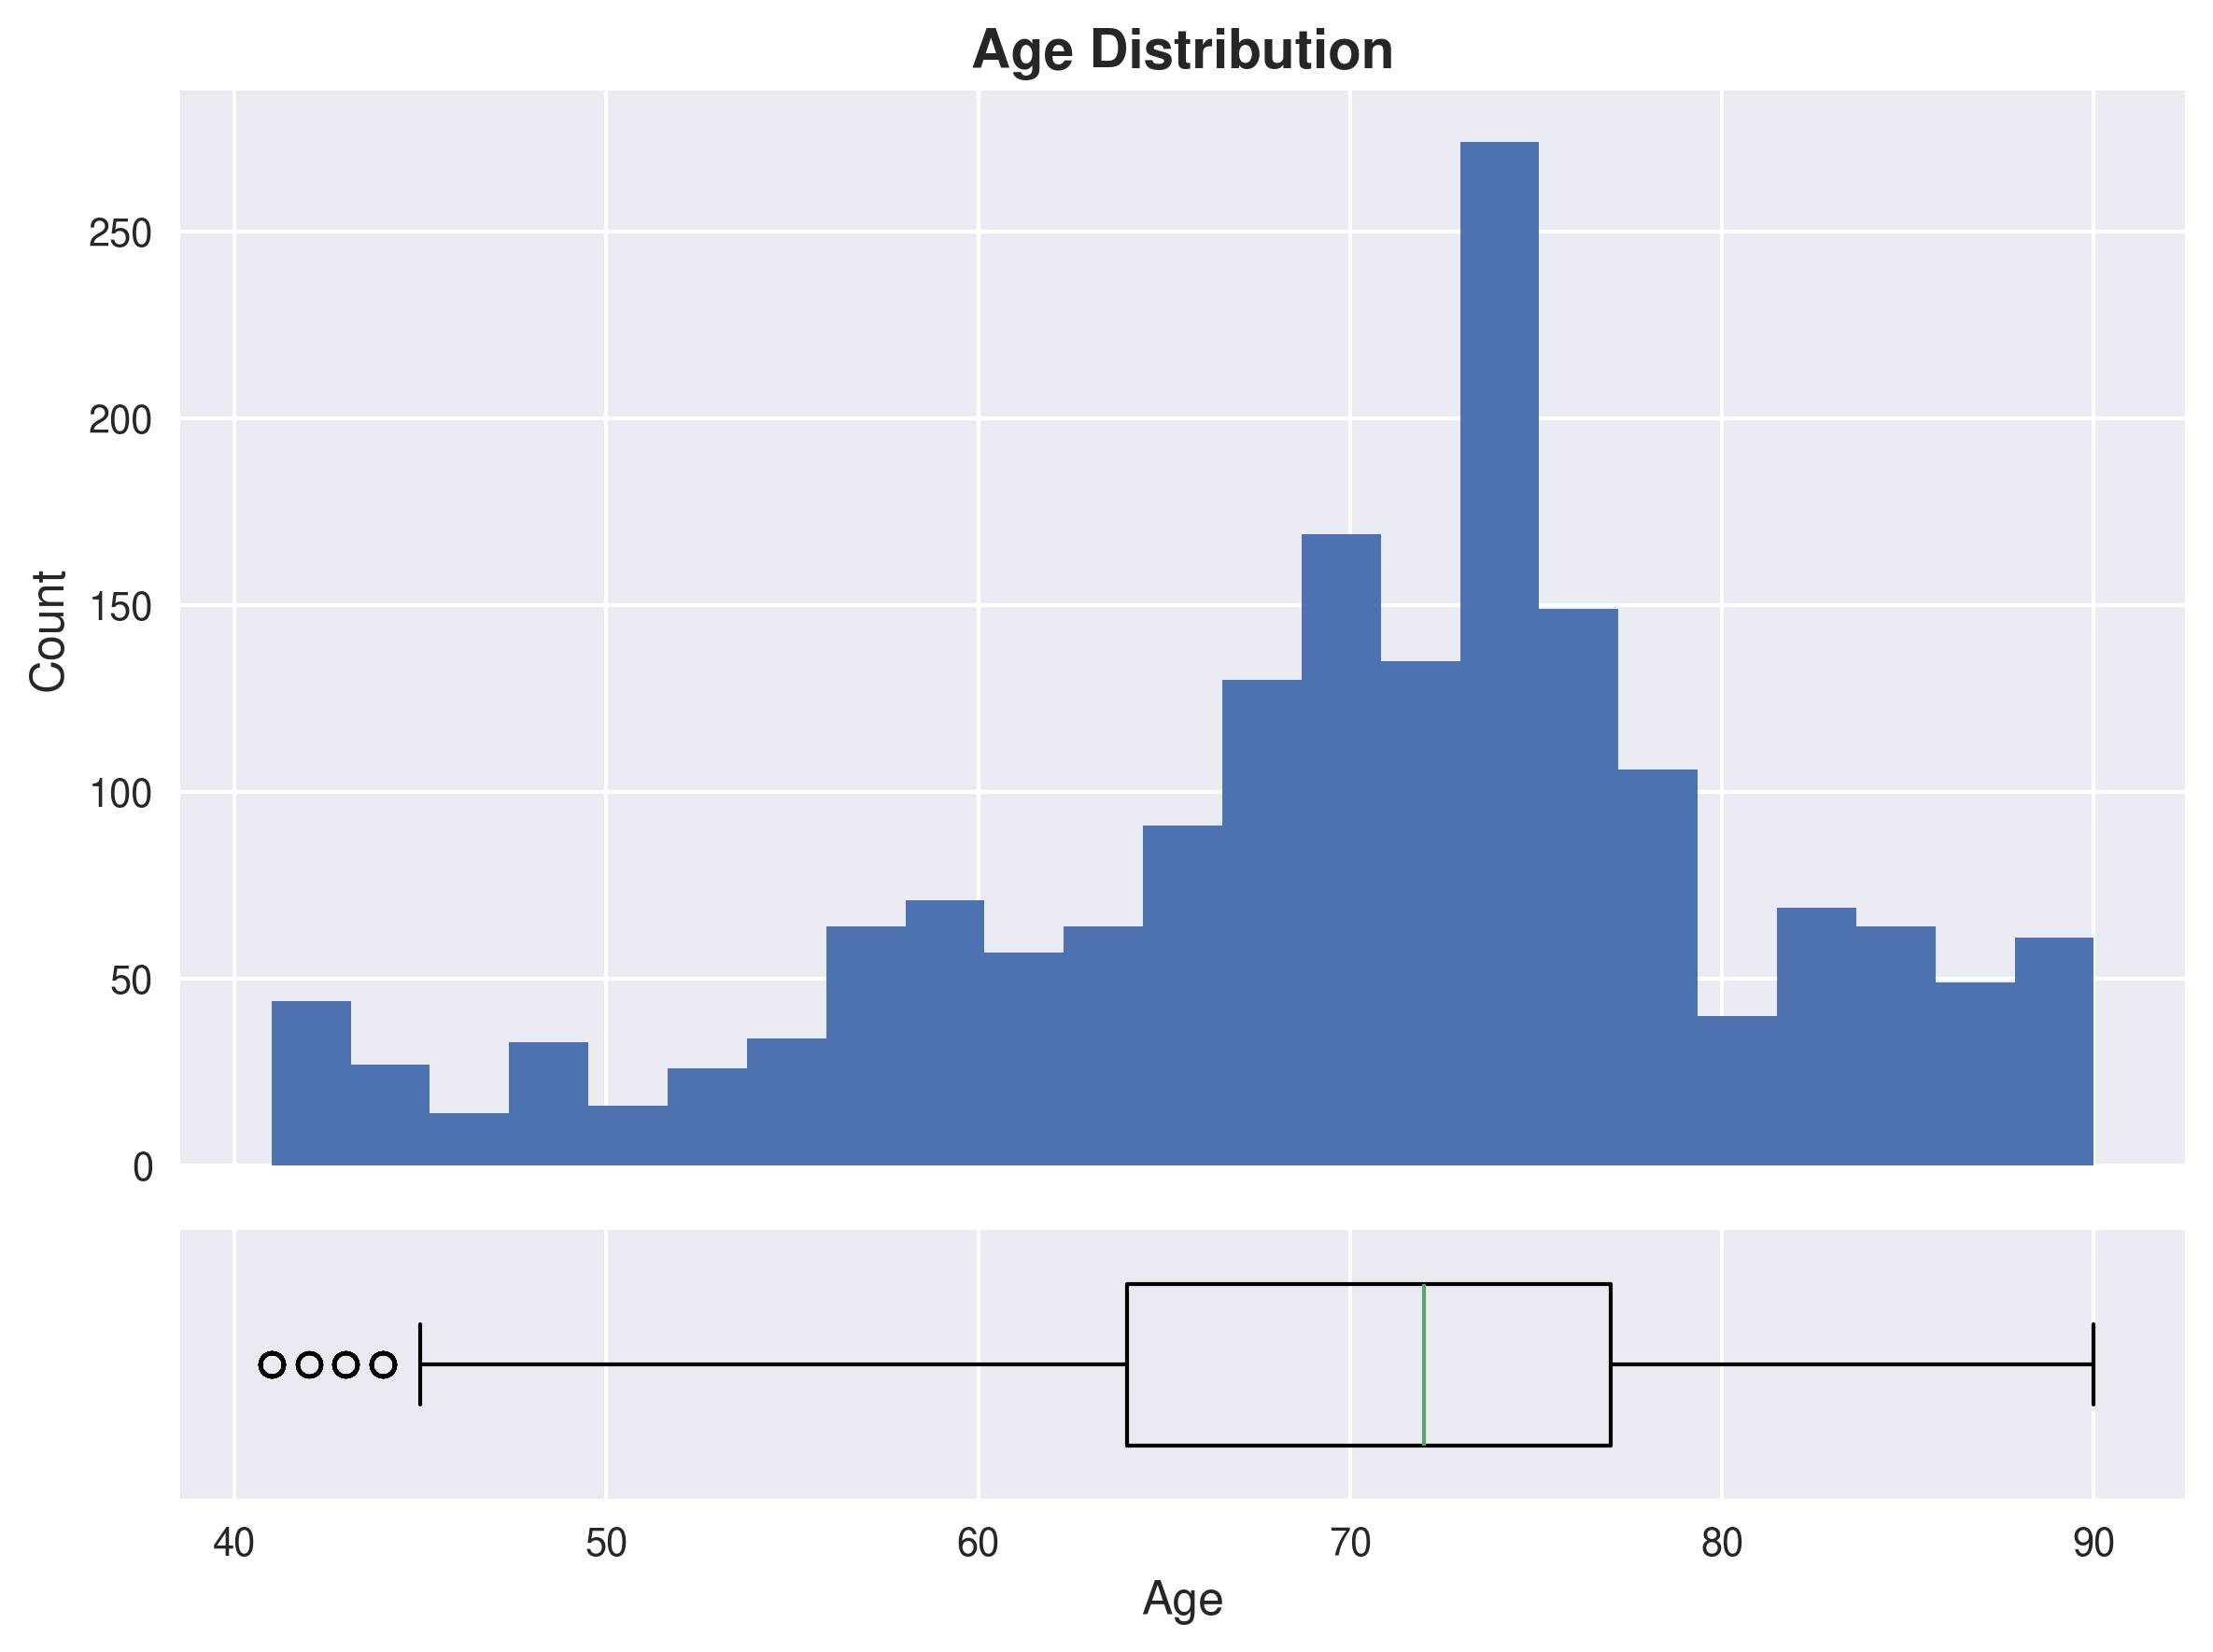

In [ ]:
histbox_plot(df, colname,
    title, x_label, y_label,
    output_dir, output_name, output_format,
    figsize, bins='auto')

In [ ]:
# # Define range
# min_age = df[colname].min()
# max_age = df[colname].max()

# # Create bins every 2 years
# bins = np.arange(min_age, max_age + 2, 2)

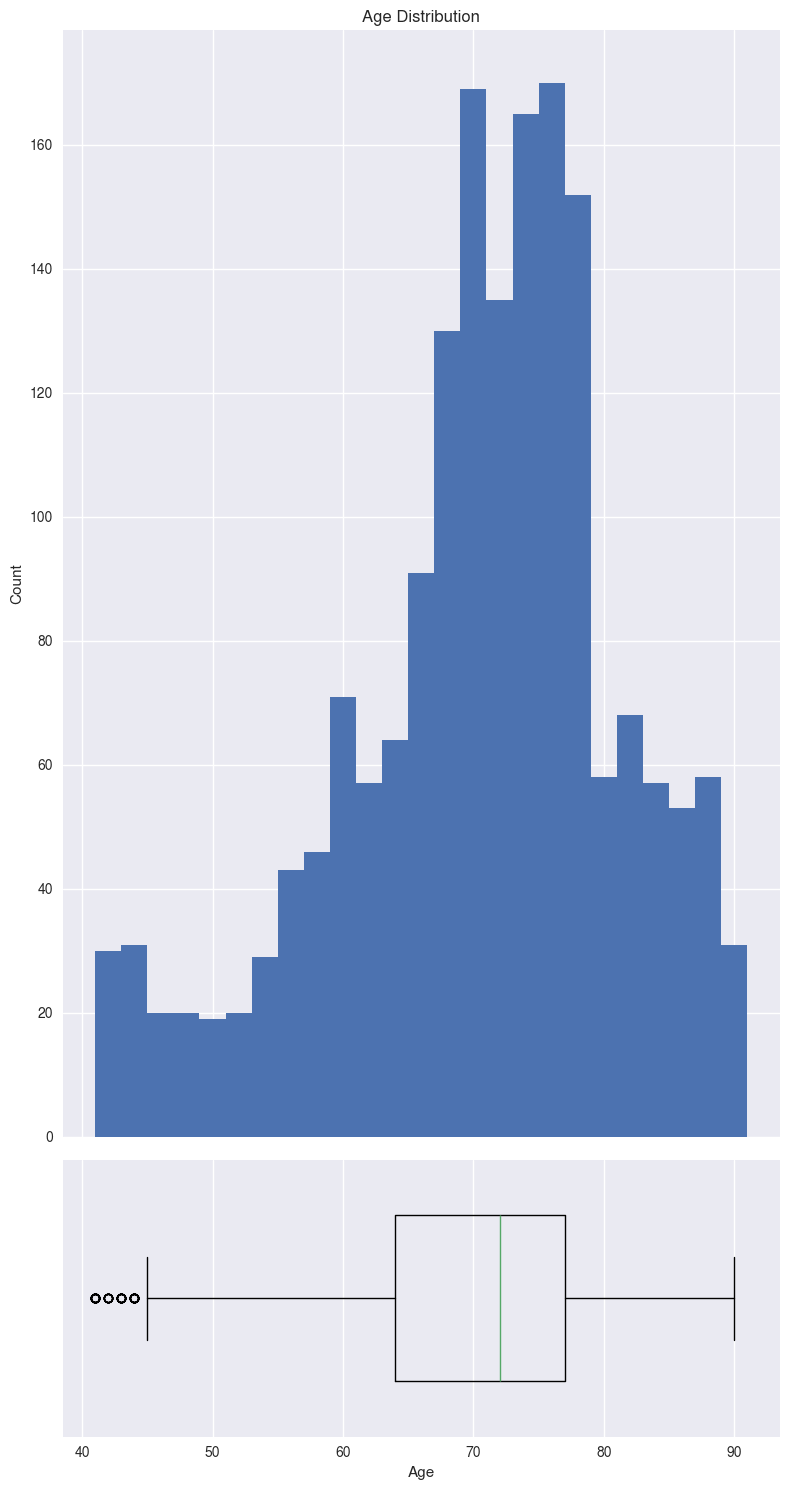

In [ ]:
# # Create figure with 2 rows (hist + boxplot)
# fig, (ax1, ax2) = plt.subplots(
#     2, 1, 
#     figsize=(8, 6),
#     sharex=True, 
#     gridspec_kw={'height_ratios': [4, 1]}
# )

# # Histogram
# ax1.hist(df[colname], bins=bins)
# ax1.set_title('Age Distribution')
# ax1.set_ylabel('Count', fontsize=12)

# # Boxplot
# ax2.boxplot(df[colname], vert=False, widths=0.6)
# ax2.set_xlabel('Age', fontsize=12)
# ax2.set_yticks([])  # optional: hide y-axis ticks

# plt.tight_layout()
# plt.savefig("../plots/1-escribe/2-age_distribution.png", dpi=300, bbox_inches='tight')
# plt.show()

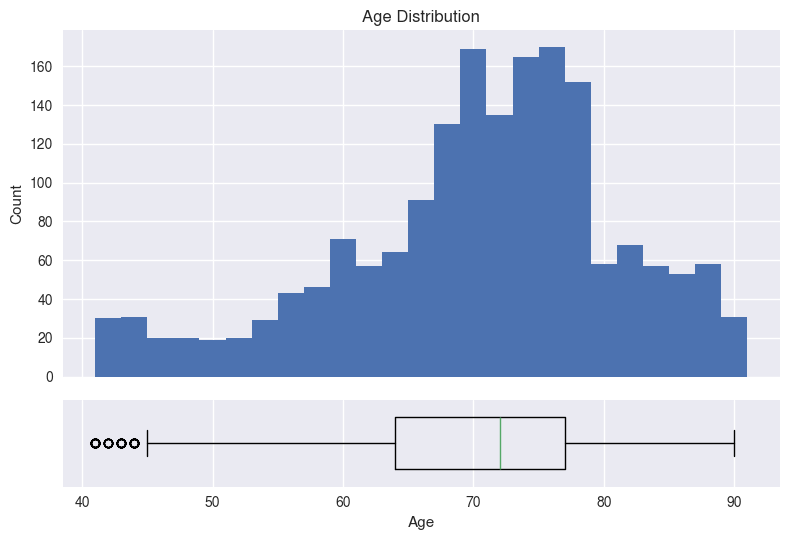

In [ ]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('Age Distribution')
ax1.set_ylabel('Count')

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Age')
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
# plt.savefig("../plots/1-escribe/2-age_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

In [14]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {44: 17, 41: 22, 43: 14, 42: 8}
Mean: 69.905
Std dev: 10.795


#### `acq_time`

In [15]:
colname = 'acq_time'

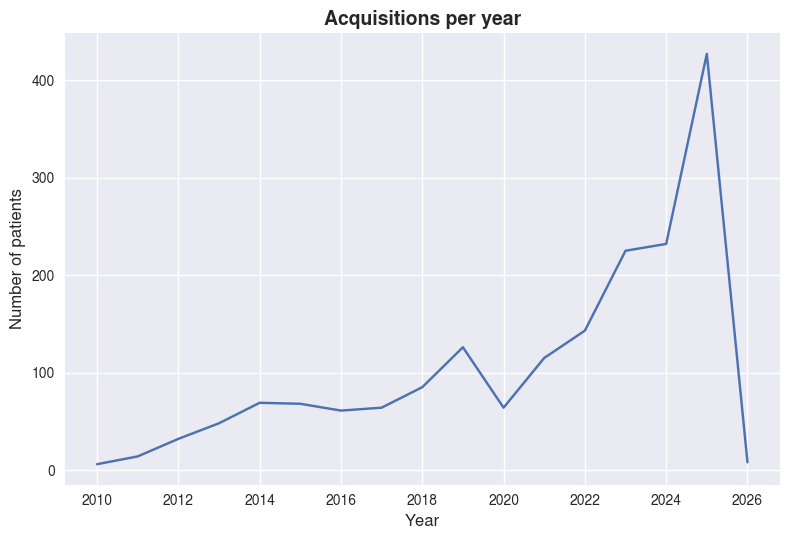

In [16]:
births_per_year = df[colname].dt.year.value_counts().sort_index()

births_per_year.plot()
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of patients', fontsize=12)
plt.title('Acquisitions per year', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig("../plots/1-escribe/3-acq_time.png", dpi=300, bbox_inches='tight')
plt.show()

#### `rr_interval`

In [19]:
colname = 'rr_interval'

In [20]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 20, 20)

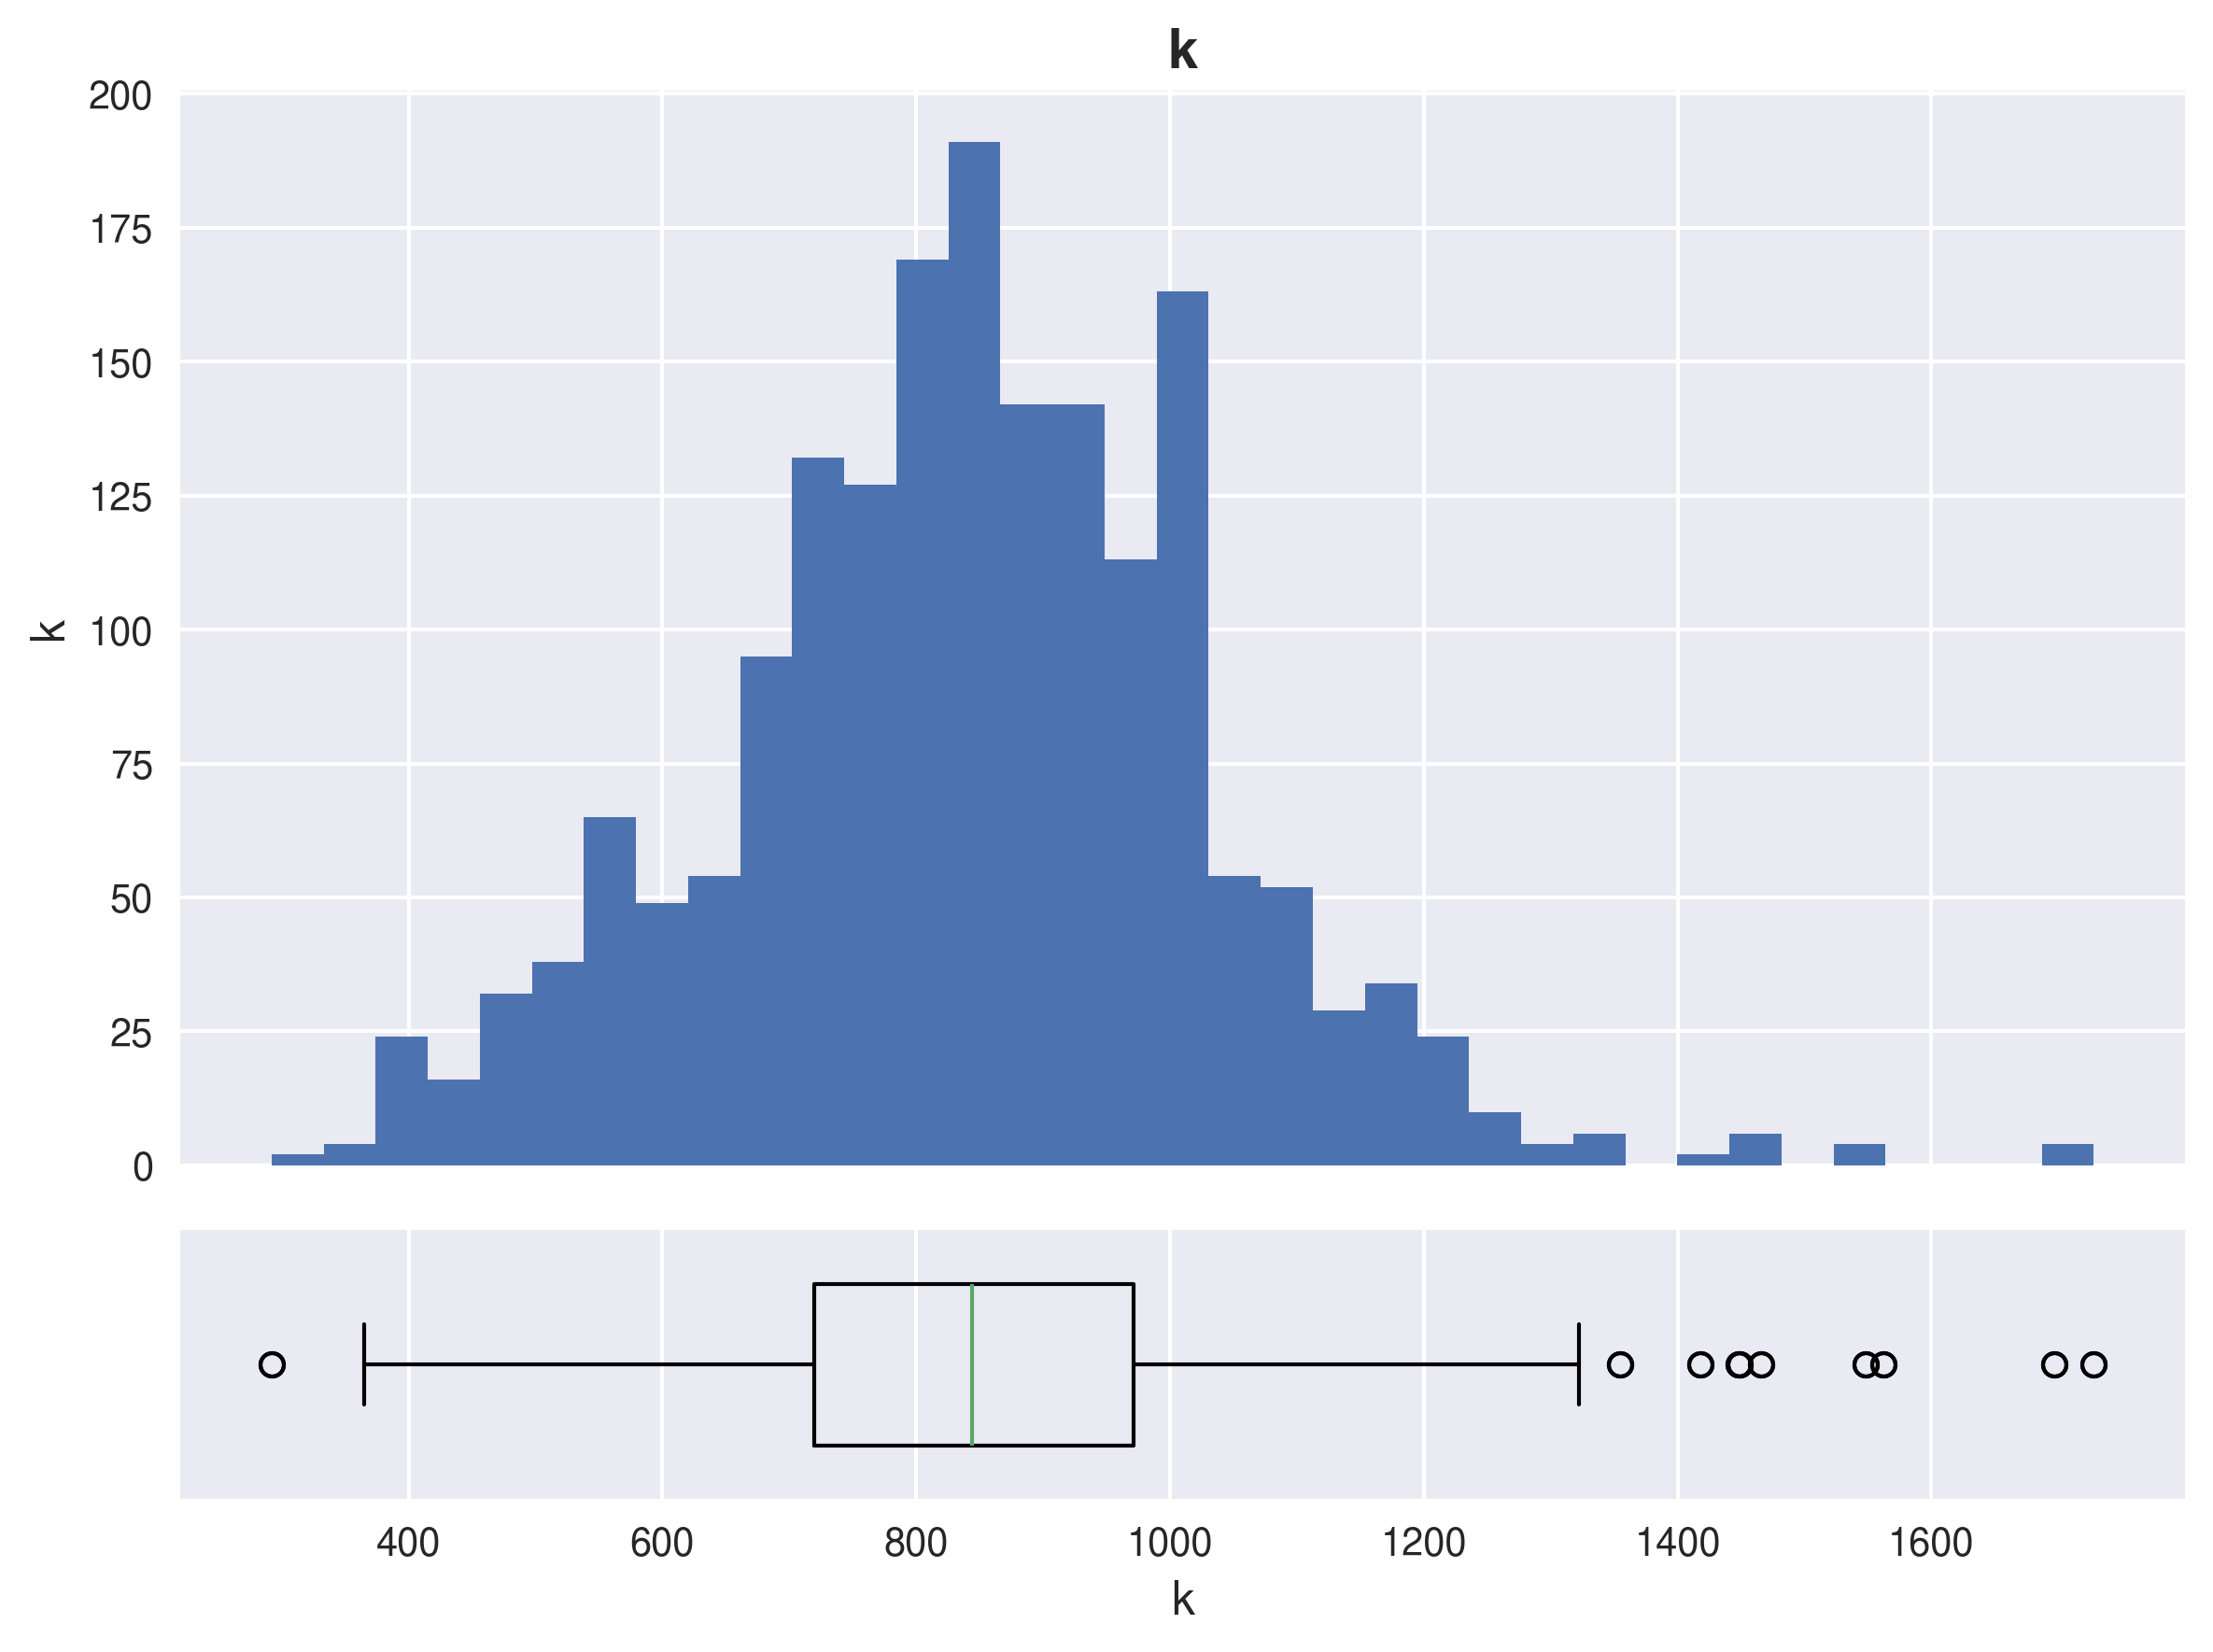

In [21]:
title = 'k'
x_label = 'k'
y_label = 'k'
output_name = 'k'
progr += 1

histbox_plot(df, colname,
    title, x_label, y_label,
    output_dir, progr, output_name, output_format,
    figsize, bins='auto')

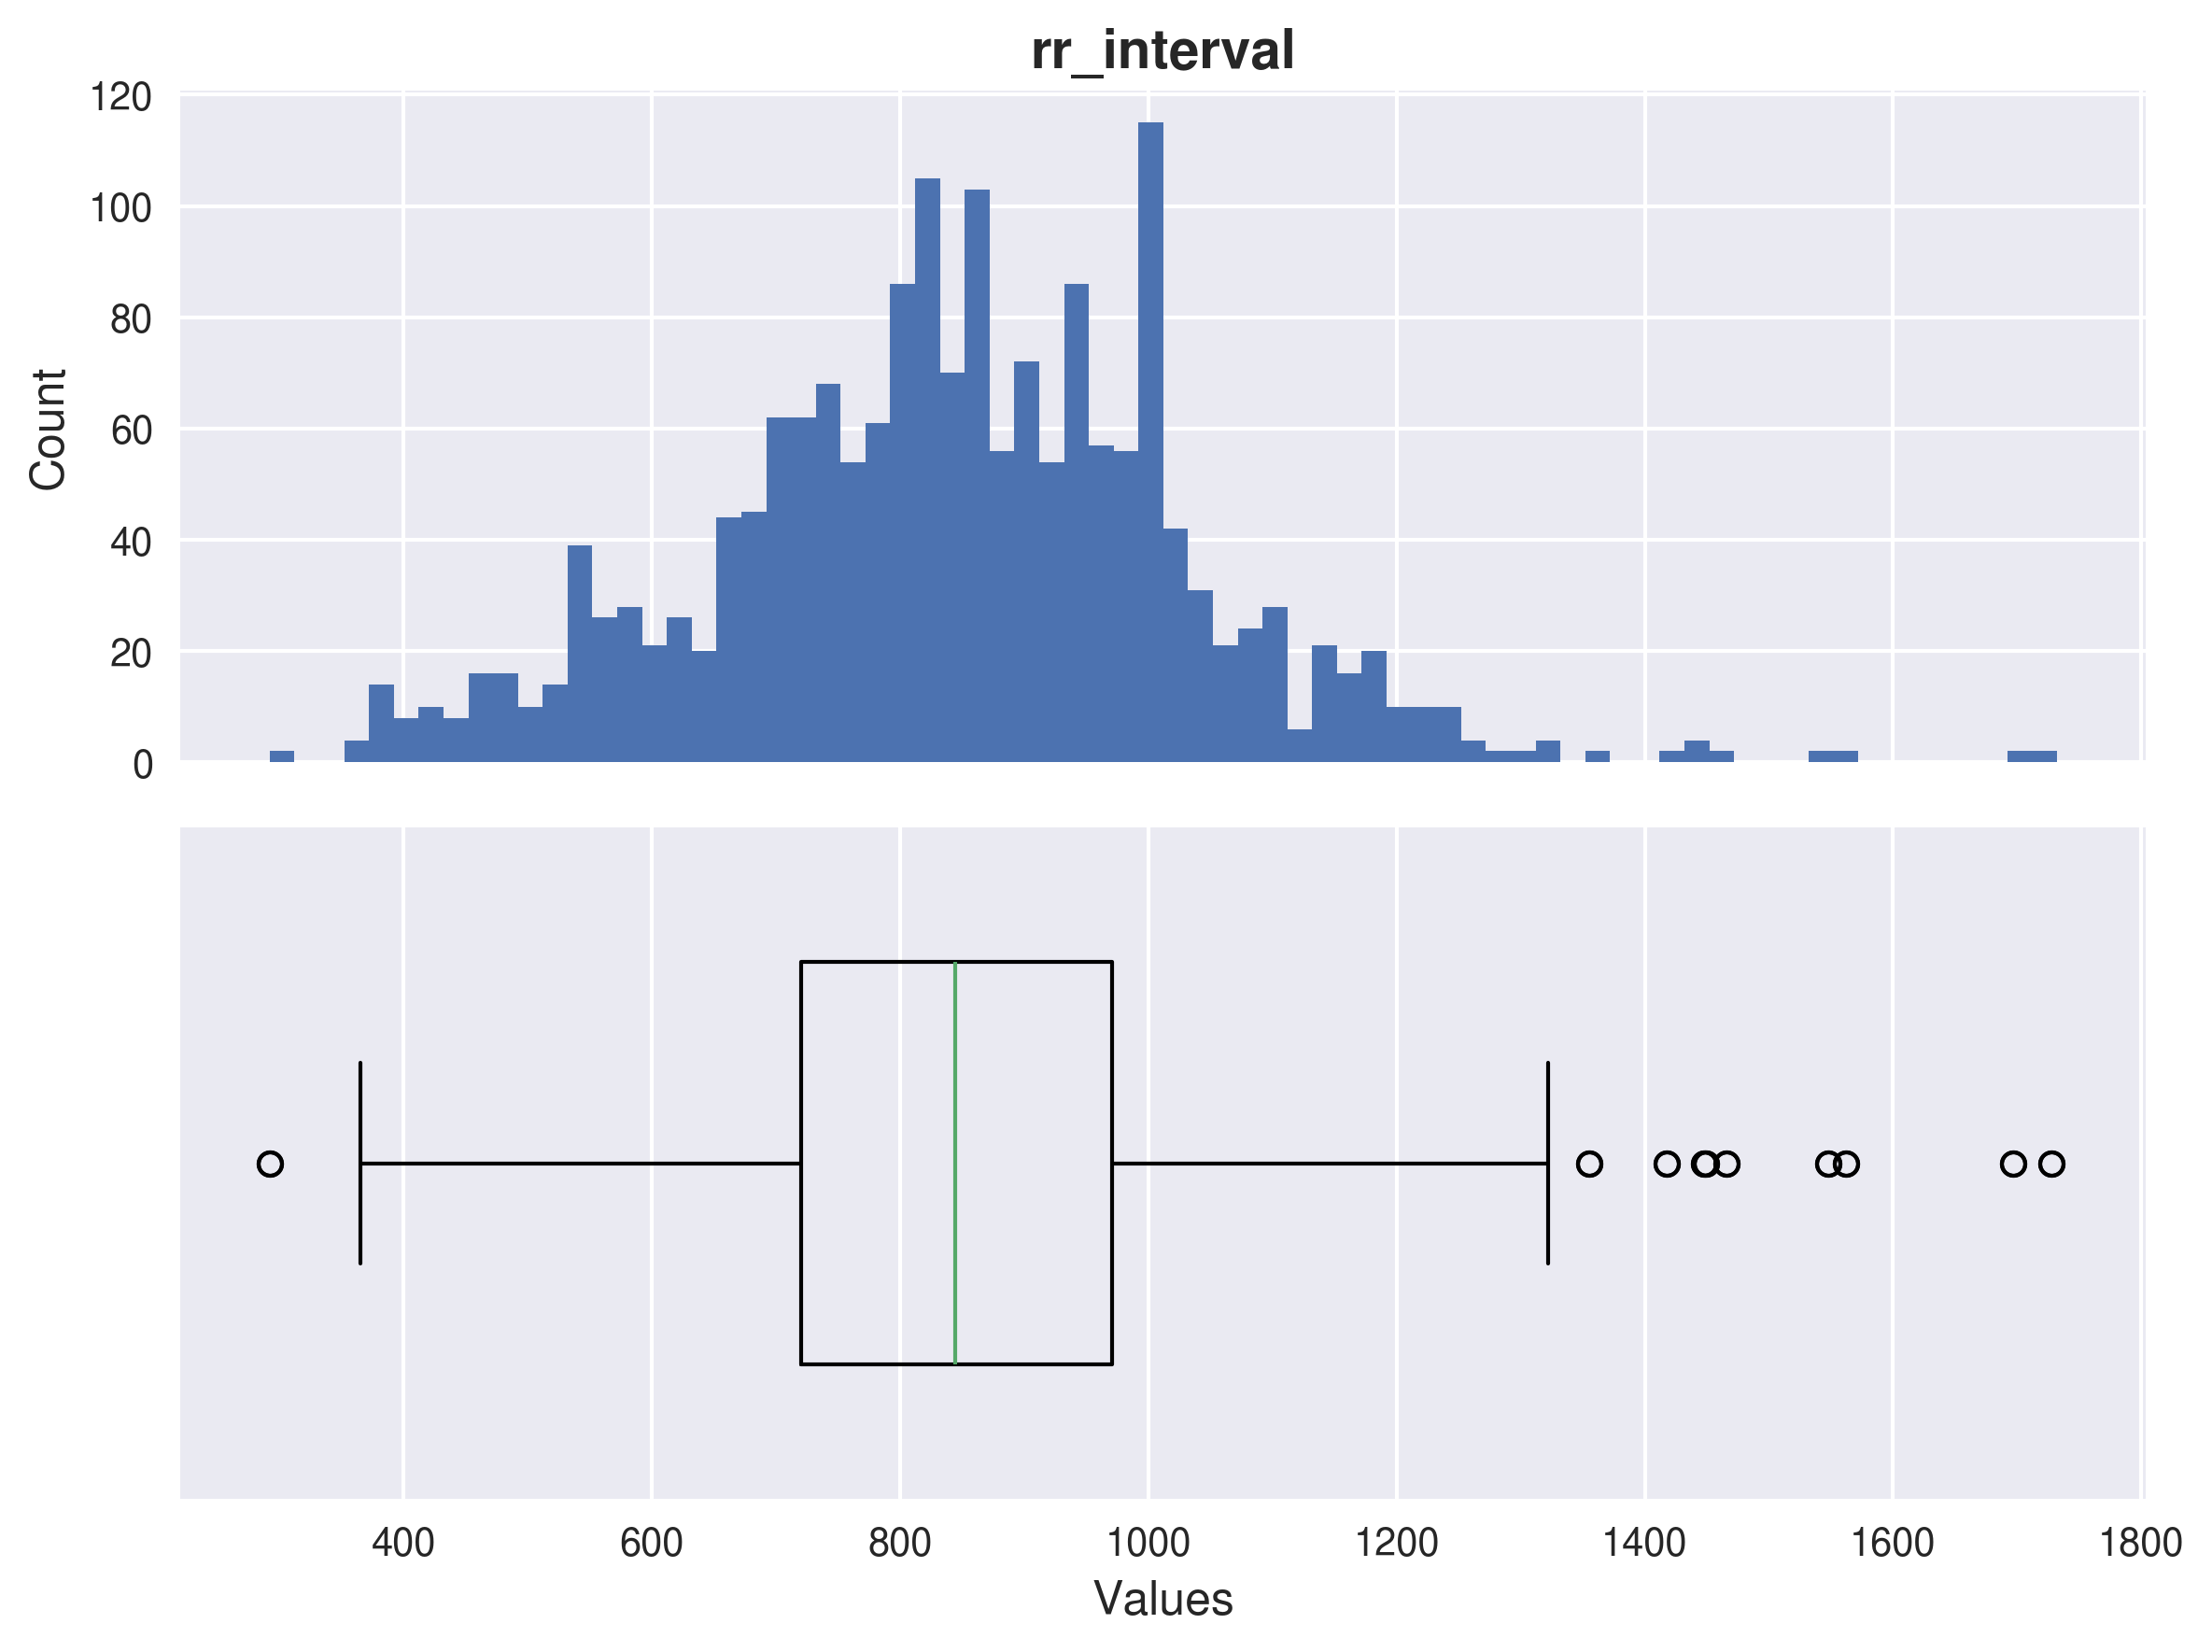

In [ ]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('rr_interval', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/4-rr_interval.png", dpi=300, bbox_inches='tight')
plt.show()

In [20]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {292: 2, 1449: 2, 1448: 2, 1562: 2, 1418: 2, 1697: 2, 1548: 2, 1355: 2, 1728: 2, 1466: 2}
Mean: 842.669
Std dev: 194.817


#### `p_onset`

In [21]:
colname = 'p_onset'

In [22]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 20, 20)

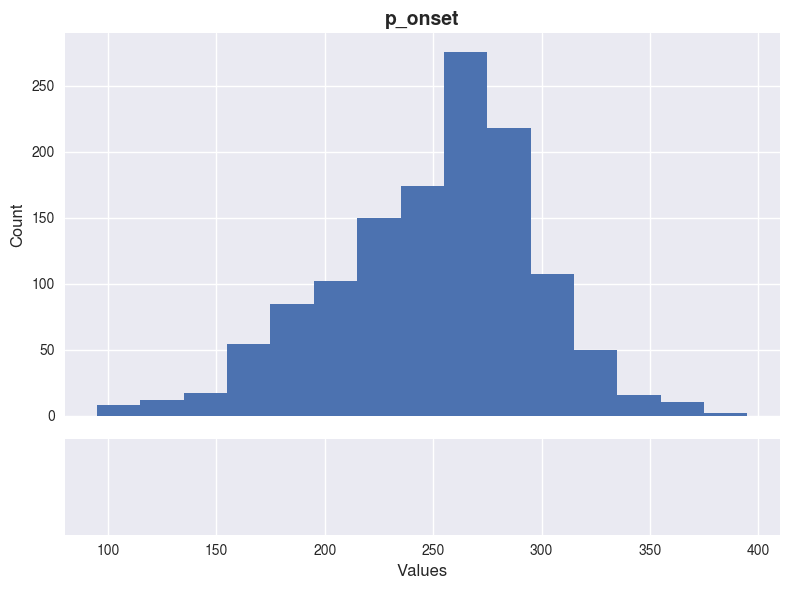

In [23]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('p_onset', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/5-p_onset.png", dpi=300, bbox_inches='tight')
plt.show()

In [24]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {}
Mean: 249.998
Std dev: 47.128


#### `p_offset`

In [25]:
colname = 'p_offset'

In [26]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins
bins = np.arange(min_age, max_age + 20, 20)

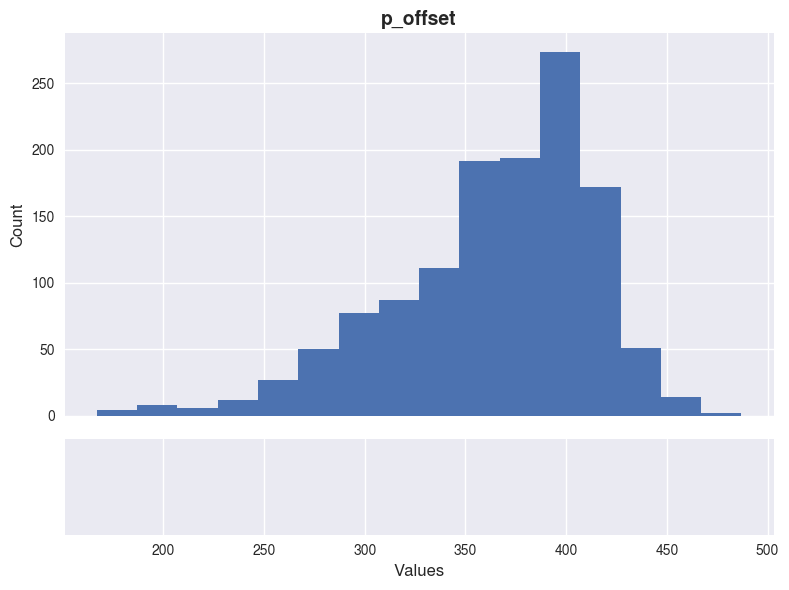

In [27]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('p_offset', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/6-p_offset.png", dpi=300, bbox_inches='tight')
plt.show()

In [28]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {}
Mean: 364.17
Std dev: 49.878


#### `qrs_onset`

In [29]:
colname = 'qrs_onset'

In [30]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

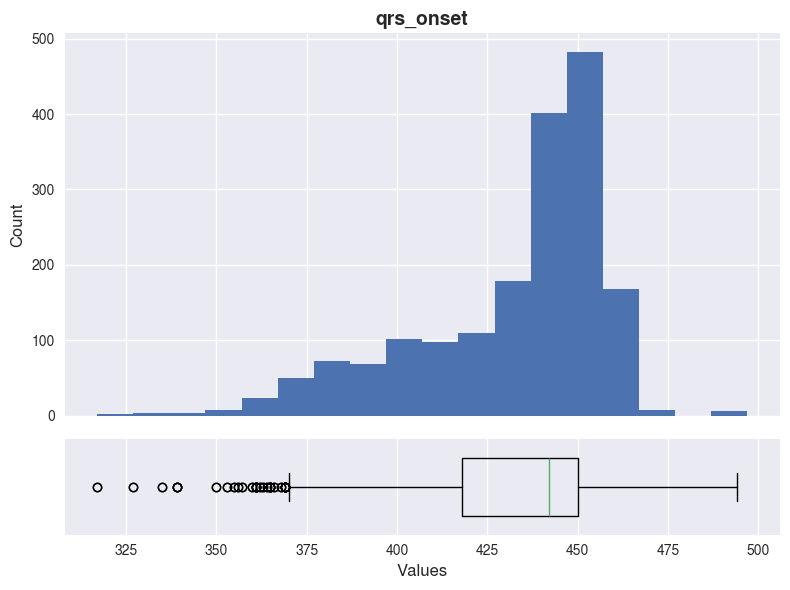

In [31]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('qrs_onset', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/7-qrs_onset.png", dpi=300, bbox_inches='tight')
plt.show()

In [32]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {355: 2, 361: 6, 362: 2, 360: 2, 356: 2, 369: 10, 357: 2, 368: 2, 339: 4, 353: 2, 327: 2, 350: 2, 364: 2, 365: 6, 366: 2, 335: 2, 363: 2, 317: 2}
Mean: 431.851
Std dev: 26.792


#### `qrs_offset`

In [33]:
colname = 'qrs_offset'

In [34]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

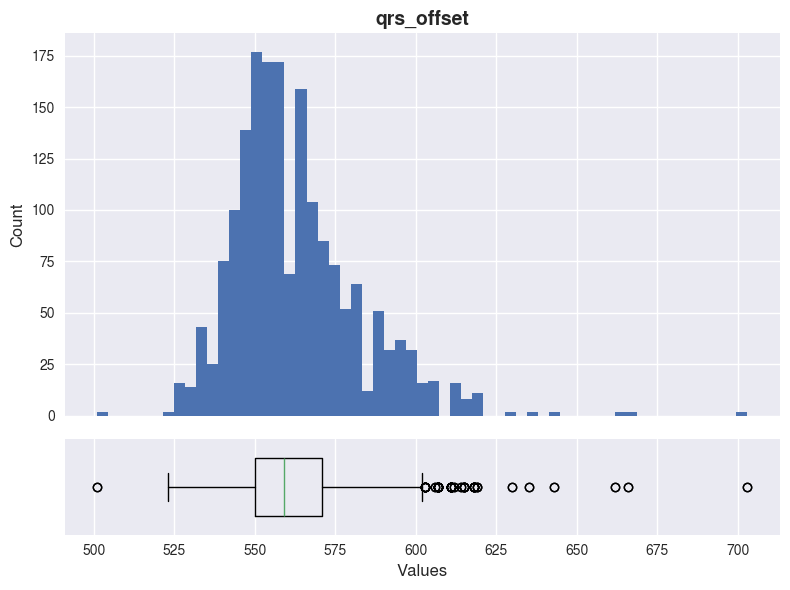

In [35]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins='auto')
ax1.set_title('qrs_offset', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/8-qrs_offset.png", dpi=300, bbox_inches='tight')
plt.show()

In [36]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {501: 2, 611: 14, 662: 2, 607: 15, 615: 6, 603: 10, 703: 2, 643: 2, 618: 8, 630: 2, 619: 3, 612: 2, 635: 2, 614: 2, 666: 2, 606: 2}
Mean: 562.771
Std dev: 19.991


#### `t_offset`

In [37]:
colname = 't_offset'

In [38]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

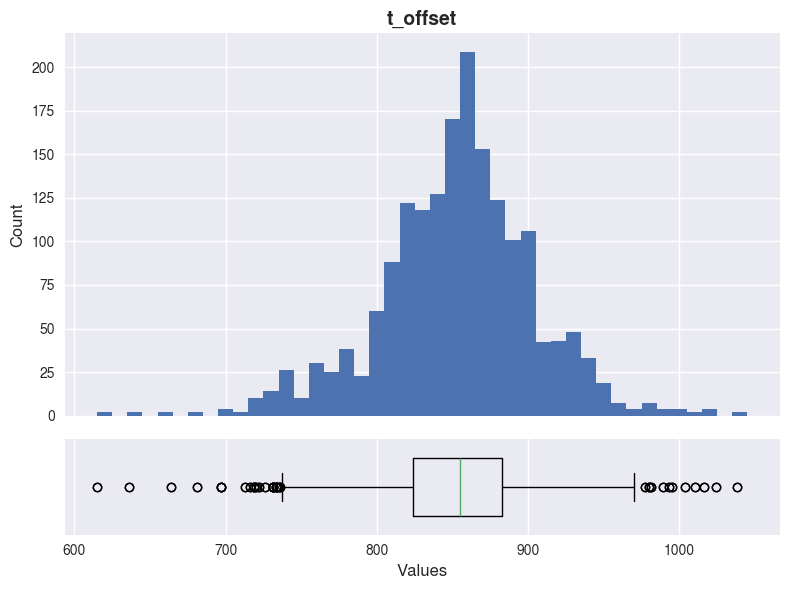

In [39]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('t_offset', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/9-t_offset.png", dpi=300, bbox_inches='tight')
plt.show()

In [40]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {719: 4, 726: 2, 615: 2, 716: 2, 734: 2, 735: 2, 722: 2, 731: 6, 733: 4, 736: 2, 720: 2, 636: 2, 697: 4, 681: 2, 713: 2, 664: 2, 989: 2, 1016: 2, 981: 2, 980: 3, 1010: 2, 977: 2, 1004: 2, 1024: 2, 1038: 2, 995: 2, 993: 2}
Mean: 852.581
Std dev: 51.652


#### `p_axis`

In [41]:
colname = 'p_axis'

In [42]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 20, 20)

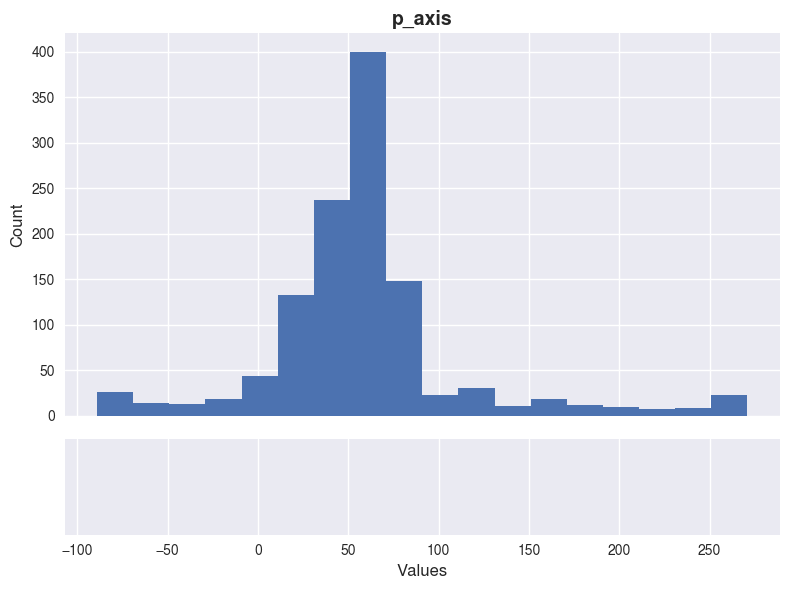

In [43]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('p_axis', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/10-p_axis.png", dpi=300, bbox_inches='tight')
plt.show()

In [44]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {}
Mean: 58.661
Std dev: 55.609


#### `qrs_axis`

In [45]:
colname = 'qrs_axis'

In [46]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

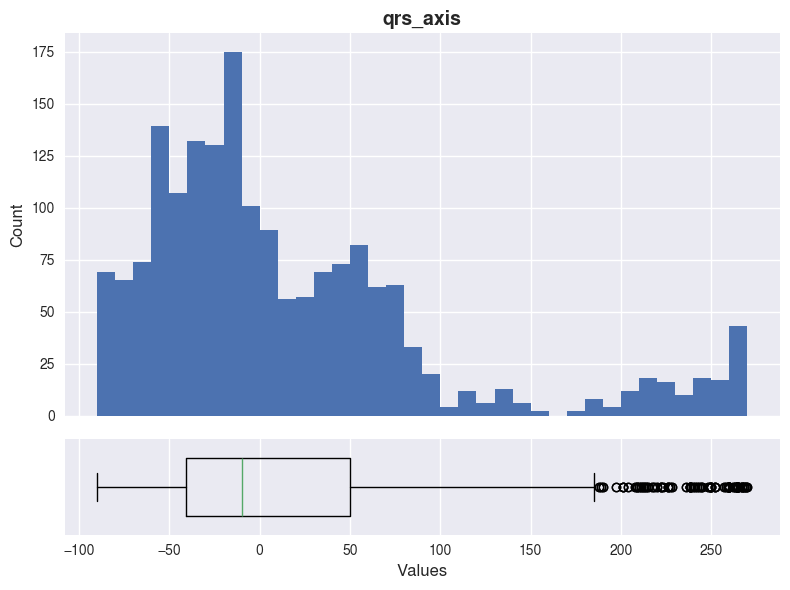

In [47]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('qrs_axis', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/11-qrs_axis.png", dpi=300, bbox_inches='tight')
plt.show()

In [48]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {209: 4, 260: 8, 222: 4, 238: 6, 211: 3, 252: 4, 239: 2, 245: 2, 249: 4, 236: 2, 241: 2, 242: 2, 248: 2, 264: 8, 214: 3, 197: 2, 243: 2, 259: 5, 215: 2, 217: 2, 226: 4, 267: 5, 270: 2, 266: 1, 268: 4, 265: 6, 263: 4, 204: 2, 218: 2, 212: 2, 201: 4, 257: 2, 262: 2, 244: 2, 210: 2, 190: 2, 220: 2, 269: 3, 213: 2, 208: 2, 189: 2, 188: 2, 240: 2, 258: 2, 250: 4, 228: 2, 223: 2, 227: 2}
Mean: 15.167
Std dev: 83.083


#### `t_axis`

In [49]:
colname = 't_axis'

In [50]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

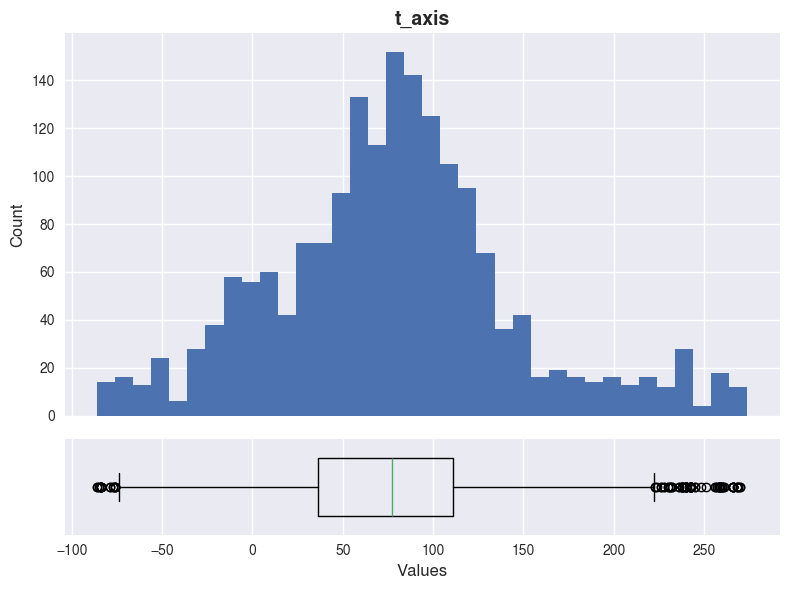

In [51]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('t_axis', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/12-t_axis.png", dpi=300, bbox_inches='tight')
plt.show()

In [52]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {-77: 2, -84: 6, -86: 2, -85: 2, -76: 4, -79: 2, 238: 6, 226: 2, 240: 8, 242: 4, 223: 2, 230: 2, 258: 4, 266: 6, 245: 2, 268: 2, 239: 2, 232: 2, 269: 2, 256: 2, 261: 2, 236: 2, 243: 6, 260: 4, 257: 2, 248: 1, 224: 1, 251: 1, 259: 4, 270: 2, 231: 3, 228: 2}
Mean: 77.01
Std dev: 67.709


#### `v_rate`

In [53]:
colname = 'v_rate'

In [54]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 5, 5)

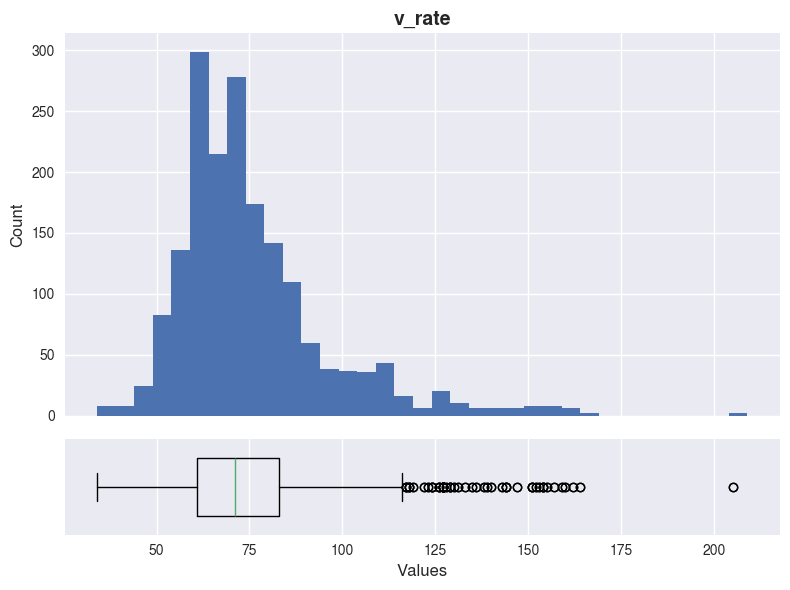

In [55]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('v_rate', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/13-v_rate.png", dpi=300, bbox_inches='tight')
plt.show()

In [56]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {159: 2, 155: 2, 129: 4, 154: 4, 131: 2, 151: 4, 130: 2, 123: 2, 127: 10, 117: 4, 152: 2, 126: 4, 140: 2, 122: 2, 128: 2, 144: 4, 118: 4, 139: 2, 205: 2, 124: 4, 136: 2, 160: 2, 147: 2, 164: 2, 119: 2, 135: 2, 133: 2, 157: 2, 143: 2, 162: 2, 138: 2, 153: 2}
Mean: 75.184
Std dev: 20.892


#### `pr_interval`

In [57]:
colname = 'pr_interval'

In [58]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

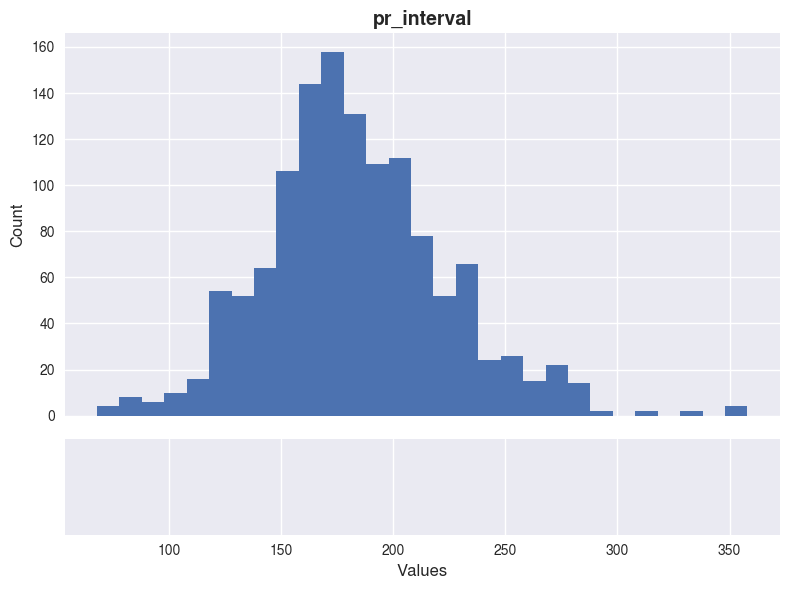

In [59]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('pr_interval', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/14-pr_interval.png", dpi=300, bbox_inches='tight')
plt.show()

In [60]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {}
Mean: 182.879
Std dev: 40.922


#### `qrs_duration`

In [61]:
colname = 'qrs_duration'

In [62]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

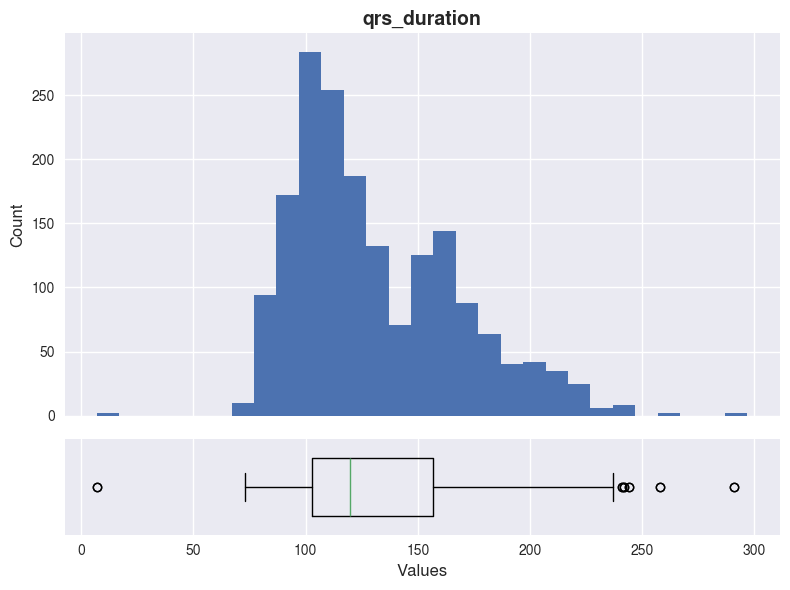

In [63]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('qrs_duration', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/15-qrs_duration.png", dpi=300, bbox_inches='tight')
plt.show()

In [64]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {7: 2, 244: 2, 242: 2, 241: 2, 291: 2, 258: 2}
Mean: 130.92
Std dev: 36.901


#### `qt_interval`

In [65]:
colname = 'qt_interval'

In [66]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 15, 15)

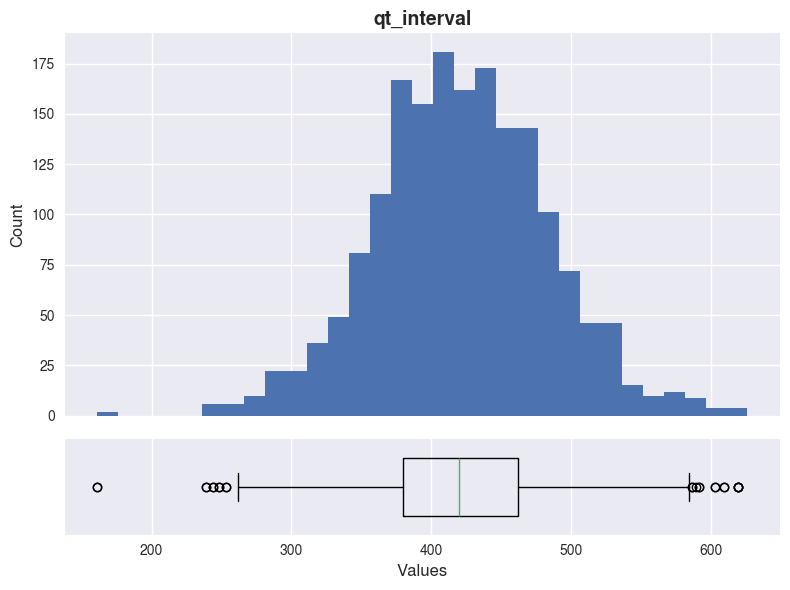

In [67]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('qt_interval', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/16-qt_interval.png", dpi=300, bbox_inches='tight')
plt.show()

In [68]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {161: 2, 253: 2, 239: 2, 248: 2, 244: 2, 591: 2, 589: 1, 619: 4, 586: 2, 603: 2, 609: 2}
Mean: 420.73
Std dev: 61.932


#### `qtc_interval`

In [69]:
colname = 'qtc_interval'

In [70]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 10, 10)

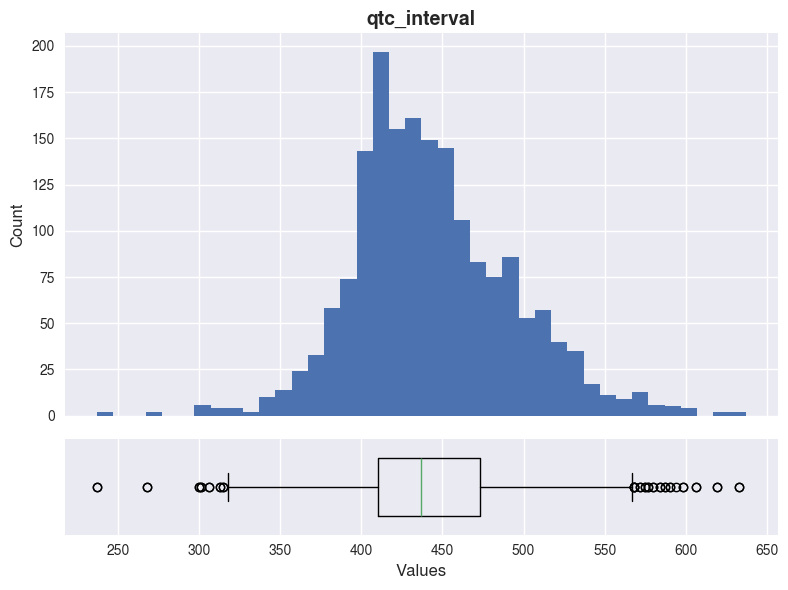

In [71]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('qtc_interval', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Values', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/17-qtc_interval.png", dpi=300, bbox_inches='tight')
plt.show()

In [72]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')

Outliers: {237: 2, 301: 2, 313: 2, 300: 2, 315: 2, 306: 2, 268: 2, 568: 4, 580: 2, 594: 1, 633: 2, 584: 2, 590: 2, 587: 2, 606: 2, 619: 2, 575: 2, 572: 2, 577: 2, 598: 2}
Mean: 442.949
Std dev: 49.567


#### ``

In [73]:
colname = ''

In [74]:
# Define range
min_age = df[colname].min()
max_age = df[colname].max()

# Create bins every 2 years
bins = np.arange(min_age, max_age + 2, 2)

KeyError: ''

In [ ]:
# Create figure with 2 rows (hist + boxplot)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(8, 6),
    sharex=True, 
    gridspec_kw={'height_ratios': [4, 1]}
)

# Histogram
ax1.hist(df[colname], bins=bins)
ax1.set_title('Age Distribution', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12)

# Boxplot
ax2.boxplot(df[colname], vert=False, widths=0.6)
ax2.set_xlabel('Age', fontsize=12)
ax2.set_yticks([])  # optional: hide y-axis ticks

plt.tight_layout()
plt.savefig("../plots/1-escribe/age_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Outliers
bp = ax2.boxplot(df[colname], vert=False)
fliers = bp['fliers'][0].get_xdata()

# convert to Python int
fliers = [int(v) for v in fliers]

outlier_counts = dict(Counter(fliers))
print(f'Outliers: {outlier_counts}')


# Mean
mean = round(df[colname].mean(), 3)
print(f'Mean: {mean}')


# stddev
stddev = round(df[colname].std(), 3)
print(f'Std dev: {stddev}')